In [1]:
import numpy as np
from scipy.optimize import root
import matplotlib.pyplot as plt




T = 7000.0  # K


S_H = 2.3e11       # cm^-3
S_Hminus = 1.6e21  # cm^-3


# -------------------------------------------------
# Equilibrium equations
# -------------------------------------------------

def equilibrium_equations(X, N):

    N_H, N_Hplus, N_Hminus, N_e = X

    x1 = N_Hplus * N_e / S_H - N_H
    x2 = N_H * N_e / S_Hminus - N_Hminus
    x3 = N_H + N_Hplus + N_Hminus + N_e - N
    x4 = N_Hplus - N_Hminus - N_e

    return [x1, x2, x3, x4]





In [2]:
#high density

N = 1.0e18  # cm^-3

guess = np.array([
    3.0e17,   # H
    3.0e17,   # H+
    1.0e14,   # H-
    3.0e17    # e-
])


# Solve
sol = root(
    equilibrium_equations,
    guess,
    args=(N,)
)


# -------------------------------------------------
# Results
# -------------------------------------------------

print("Success:", sol.success)
print("Message:", sol.message)

N_H, N_Hplus, N_Hminus, N_e = sol.x

print()
print("Equilibrium populations:")
print("H  =", N_H, "cm^-3")
print("H+ =", N_Hplus, "cm^-3")
print("H- =", N_Hminus, "cm^-3")
print("e- =", N_e, "cm^-3")


# -------------------------------------------------
# Checks
# -------------------------------------------------

print()
print("Checks:")

# Total particle density
N_total_check = N_H + N_Hplus + N_Hminus + N_e

print("Given N      =", N)
print("Calculated N =", N_total_check)


# Charge neutrality
charge_check = N_Hplus - N_Hminus - N_e

print("Charge residual =", charge_check)


# Saha equation for H
saha_H_check = N_Hplus * N_e / N_H

print("Calculated S_H =", saha_H_check)
print("Expected S_H   =", S_H)


# Saha equation for H-
saha_Hminus_check = N_H * N_e / N_Hminus

print("Calculated S_Hminus =", saha_Hminus_check)
print("Expected S_Hminus   =", S_Hminus)

Success: True
Message: The solution converged.

Equilibrium populations:
H  = 9.990409944668658e+17 cm^-3
H+ = 479502766567091.5 cm^-3
H- = 299214995446.3929 cm^-3
e- = 479203551571645.06 cm^-3

Checks:
Given N      = 1e+18
Calculated N = 9.999999999999999e+17
Charge residual = 0.0625
Calculated S_H = 230000000000.0006
Expected S_H   = 230000000000.0
Calculated S_Hminus = 1.5999999999998718e+21
Expected S_Hminus   = 1.6e+21


In [3]:
N_values = np.logspace(18,8,101)

In [4]:
print(N_values[:5])

[1.00000000e+18 7.94328235e+17 6.30957344e+17 5.01187234e+17
 3.98107171e+17]


In [5]:
H_values =[]
Hplus_values=[]
Hminus_values=[]
e_values=[]

In [6]:
guess = np.array([
    N_H,
    N_Hplus,
    N_Hminus,
    N_e
])

In [7]:
for i, N in enumerate(N_values):

    sol = root(
        equilibrium_equations,
        guess,
        args=(N,)
    )

    if not sol.success:
        print("Solver failed at N =", N)

    N_H, N_Hplus, N_Hminus, N_e = sol.x

    H_values.append(N_H)
    Hplus_values.append(N_Hplus)
    Hminus_values.append(N_Hminus)
    e_values.append(N_e)

    if i < len(N_values) - 1:
        scale = N_values[i + 1] / N
        guess = sol.x * scale

In [8]:
print("Number of solutions:", len(H_values))

print("Last density:", N_values[-1])

print("H  =", H_values[-1])
print("H+ =", Hplus_values[-1])
print("H- =", Hminus_values[-1])
print("e- =", e_values[-1])

Number of solutions: 101
Last density: 100000000.0
H  = 10867.20291034113
H+ = 49994566.39854496
H- = 3.3956318330686e-10
e- = 49994566.39854496


In [9]:
H_values = np.array(H_values)
Hplus_values = np.array(Hplus_values)
Hminus_values = np.array(Hminus_values)
e_values = np.array(e_values)

In [10]:
N_values = N_values[::-1]

H_values = H_values[::-1]
Hplus_values = Hplus_values[::-1]
Hminus_values = Hminus_values[::-1]
e_values = e_values[::-1]

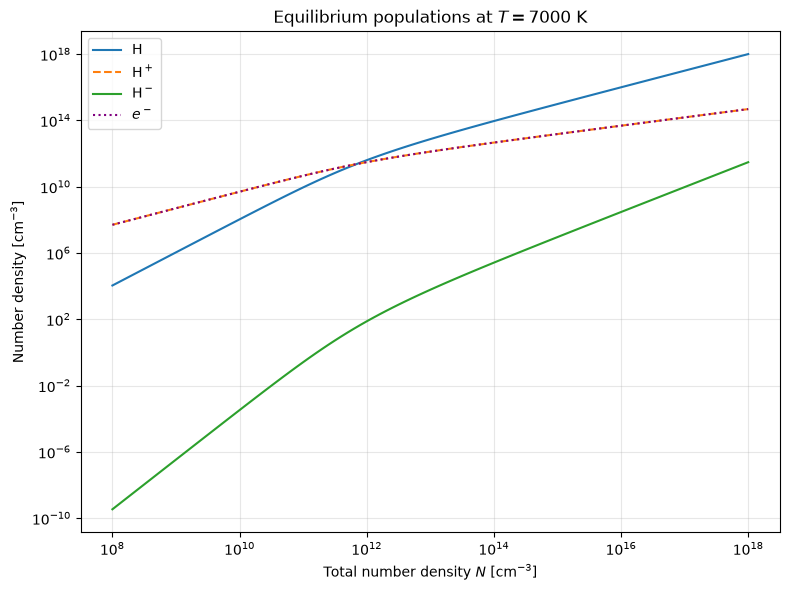

In [11]:
plt.figure(figsize=(8, 6))

plt.loglog(N_values, H_values, label=r'$\mathrm{H}$')
plt.loglog(N_values, Hplus_values, '--', label=r'$\mathrm{H^+}$')
plt.loglog(N_values, Hminus_values, label=r'$\mathrm{H^-}$')
plt.loglog(N_values, e_values, ':', color='purple', label=r'$e^-$')

plt.xlabel(r'Total number density $N$ [cm$^{-3}$]')
plt.ylabel(r'Number density [cm$^{-3}$]')

plt.title(r'Equilibrium populations at $T=7000$ K')

plt.legend()
plt.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.savefig('eq7000.png', dpi=300)
plt.show()

In [12]:
f_H = H_values / N_values
f_Hplus = Hplus_values / N_values
f_Hminus = Hminus_values / N_values
f_e = e_values / N_values

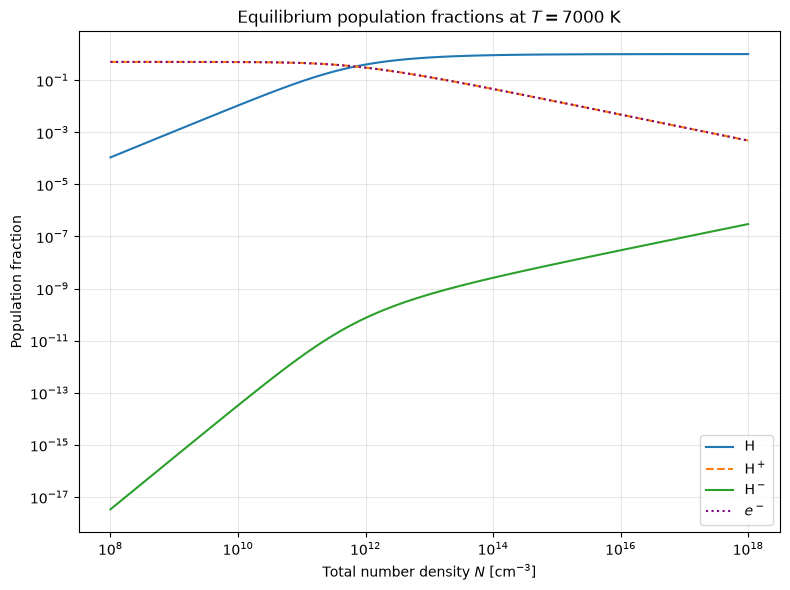

In [13]:
plt.figure(figsize=(8, 6))

plt.loglog(N_values, f_H,
           label=r'$\mathrm{H}$')

plt.loglog(N_values, f_Hplus,
           label=r'$\mathrm{H^+}$',
           linestyle='--')

plt.loglog(N_values, f_Hminus,
           label=r'$\mathrm{H^-}$')

plt.loglog(N_values, f_e,
           label=r'$e^-$',
           linestyle=':', color='purple')

plt.xlabel(r'Total number density $N$ [cm$^{-3}$]')
plt.ylabel('Population fraction')

plt.title(r'Equilibrium population fractions at $T=7000$ K')

plt.legend()
plt.grid(True, which='both', alpha=0.3)

plt.tight_layout()

plt.savefig('pop7000.png', dpi=300)
plt.show()

In [14]:
difference = np.abs(H_values - Hplus_values)

index = np.argmin(difference)

N_transition = N_values[index]

print("Transition density =", N_transition, "cm^-3")
print("H fraction =", f_H[index])
print("H+ fraction =", f_Hplus[index])

Transition density = 100000000.0 cm^-3
H fraction = 0.0001086720291034113
H+ fraction = 0.4999456639854496


In [15]:
difference = np.abs(f_H - f_Hplus)

index = np.argmin(difference)

N_transition = N_values[index]

print("Transition density =", N_transition, "cm^-3")
print("H fraction =", f_H[index])
print("H+ fraction =", f_Hplus[index])
print("e- fraction =", f_e[index])

Transition density = 630957344480.1943 cm^-3
H fraction = 0.3185130611586283
H+ fraction = 0.34074346942068584
e- fraction = 0.3407434693778867


In [16]:
print(
    f"{'N':>12} "
    f"{'H':>12} "
    f"{'H+':>12} "
    f"{'H-':>12} "
    f"{'e-':>12}"
)

for i in range(0, 101, 20):

    print(
        f"{N_values[i]:12.3e} "
        f"{H_values[i]:12.3e} "
        f"{Hplus_values[i]:12.3e} "
        f"{Hminus_values[i]:12.3e} "
        f"{e_values[i]:12.3e}"
    )

           N            H           H+           H-           e-
   1.000e+08    1.087e+04    4.999e+07    3.396e-10    4.999e+07
   1.000e+10    1.064e+08    4.947e+09    3.289e-04    4.947e+09
   1.000e+12    3.962e+11    3.019e+11    7.476e+01    3.019e+11
   1.000e+14    9.086e+13    4.571e+12    2.596e+05    4.571e+12
   1.000e+16    9.905e+15    4.773e+13    2.955e+08    4.773e+13
   1.000e+18    9.990e+17    4.795e+14    2.992e+11    4.792e+14


In [17]:
N_check = (
    H_values
    + Hplus_values
    + Hminus_values
    + e_values
)

density_error = np.abs(
    (N_check - N_values) / N_values
)

print(
    "Maximum relative density error =",
    np.max(density_error)
)

Maximum relative density error = 2.00270030976389e-14


In [18]:
charge_check = (
    Hplus_values
    - Hminus_values
    - e_values
)

charge_error = (
    np.abs(charge_check) / N_values
)

print(
    "Maximum relative charge error =",
    np.max(charge_error)
)

Maximum relative charge error = 7.665669041472113e-17


In [19]:
S_H_check = (
    Hplus_values * e_values / H_values
)

S_Hminus_check = (
    H_values * e_values / Hminus_values
)

S_H_error = np.abs(
    (S_H_check - S_H) / S_H
)

S_Hminus_error = np.abs(
    (S_Hminus_check - S_Hminus) / S_Hminus
)

print(
    "Maximum relative S_H error =",
    np.max(S_H_error)
)

print(
    "Maximum relative S_Hminus error =",
    np.max(S_Hminus_error)
)

Maximum relative S_H error = 2.906865658967391e-12
Maximum relative S_Hminus error = 7.68732971008e-09


In [21]:
# Part B

from scipy.integrate import solve_ivp

# Forward rate coefficients at T = 7000 K
alpha1 = 3.4e-13
alpha2 = 2.8e-15
alpha3 = 8.3e-9

# Reverse rates from detailed balance
zeta1 = alpha1 * S_H
zeta2 = alpha2 * S_Hminus
zeta3 = alpha3 * S_H / S_Hminus

print("zeta1 =", zeta1, "s^-1")
print("zeta2 =", zeta2, "s^-1")
print("zeta3 =", zeta3, "cm^3 s^-1")

zeta1 = 0.0782 s^-1
zeta2 = 4480000.0 s^-1
zeta3 = 1.193125e-18 cm^3 s^-1


In [22]:
#initial population

N_H0 = 1e17
N_Hplus0 = 2e17
N_Hminus0 = 1e17

# From charge neutrality
N_e0 = N_Hplus0 - N_Hminus0

y0 = [
    N_H0,
    N_Hplus0,
    N_Hminus0,
    N_e0
]

print("Initial populations:")
print("H  =", N_H0)
print("H+ =", N_Hplus0)
print("H- =", N_Hminus0)
print("e- =", N_e0)

Initial populations:
H  = 1e+17
H+ = 2e+17
H- = 1e+17
e- = 1e+17


In [23]:
def rate_equations(t, y):

    N_H, N_Hplus, N_Hminus, N_e = y

In [25]:
    # Reaction 1: H+ + e- <-> H + photon
    R1_forward = alpha1 * N_Hplus * N_e
    R1_reverse = zeta1 * N_H

    # Reaction 2: H + e- <-> H- + photon
    R2_forward = alpha2 * N_H * N_e
    R2_reverse = zeta2 * N_Hminus

    # Reaction 3: H+ + H- <-> 2H
    R3_forward = alpha3 * N_Hplus * N_Hminus
    R3_reverse = zeta3 * N_H**2

In [26]:
    dH_dt = (
        R1_forward - R1_reverse
        - R2_forward + R2_reverse
        + 2 * R3_forward - 2 * R3_reverse
    )

In [27]:
    dHplus_dt = (
        -R1_forward + R1_reverse
        - R3_forward + R3_reverse
    )

In [28]:
    dHminus_dt = (
        R2_forward - R2_reverse
        - R3_forward + R3_reverse
    )

In [29]:
    de_dt = (
        -R1_forward + R1_reverse
        - R2_forward + R2_reverse
    )

In [34]:
def rate_equations(t, y):

    N_H, N_Hplus, N_Hminus, N_e = y

    # Reaction 1: H+ + e- <-> H + photon
    R1_forward = alpha1 * N_Hplus * N_e
    R1_reverse = zeta1 * N_H

    # Reaction 2: H + e- <-> H- + photon
    R2_forward = alpha2 * N_H * N_e
    R2_reverse = zeta2 * N_Hminus

    # Reaction 3: H+ + H- <-> 2H
    R3_forward = alpha3 * N_Hplus * N_Hminus
    R3_reverse = zeta3 * N_H**2

    # Population derivatives
    dH_dt = (
        R1_forward - R1_reverse
        - R2_forward + R2_reverse
        + 2 * R3_forward - 2 * R3_reverse
    )

    dHplus_dt = (
        -R1_forward + R1_reverse
        - R3_forward + R3_reverse
    )

    dHminus_dt = (
        R2_forward - R2_reverse
        - R3_forward + R3_reverse
    )

    de_dt = (
        -R1_forward + R1_reverse
        - R2_forward + R2_reverse
    )

    return [dH_dt, dHplus_dt, dHminus_dt, de_dt]

In [35]:
t_start = 0.0
t_end = 1.0

t_eval = np.logspace(-12, 0, 500)

In [36]:
solution = solve_ivp(
    rate_equations,
    (t_start, t_end),
    y0,
    method="BDF",
    t_eval=t_eval,
    rtol=1e-8,
    atol=1e-3
)

print("Success:", solution.success)
print("Message:", solution.message)

Success: True
Message: The solver successfully reached the end of the integration interval.


In [37]:
t = solution.t

N_H_t = solution.y[0]
N_Hplus_t = solution.y[1]
N_Hminus_t = solution.y[2]
N_e_t = solution.y[3]

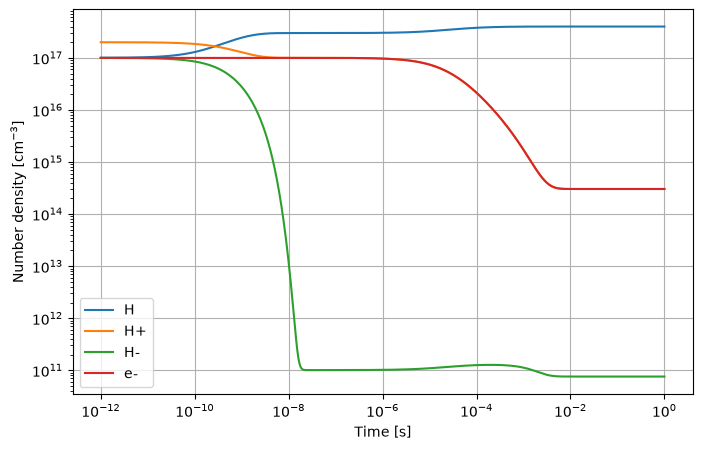

In [40]:
plt.figure(figsize=(8, 5))

plt.loglog(t, N_H_t, label="H")
plt.loglog(t, N_Hplus_t, label="H+")
plt.loglog(t, N_Hminus_t, label="H-")
plt.loglog(t, N_e_t, label="e-")

plt.xlabel("Time [s]")
plt.ylabel("Number density [cm$^{-3}$]")
plt.legend()
plt.grid()

plt.savefig("pop.png", dpi=300)
plt.show()

In [39]:
print("Final populations:")
print("H  =", N_H_t[-1])
print("H+ =", N_Hplus_t[-1])
print("H- =", N_Hminus_t[-1])
print("e- =", N_e_t[-1])

print("\nFinal hydrogen nuclei:")
print(N_H_t[-1] + N_Hplus_t[-1] + N_Hminus_t[-1])

print("\nFinal charge:")
print(N_Hplus_t[-1] - N_Hminus_t[-1] - N_e_t[-1])

Final populations:
H  = 3.996966864015515e+17
H+ = 303237865387084.5
H- = 75733062332.89684
e- = 303162132324759.25

Final hydrogen nuclei:
4.000000000000009e+17

Final charge:
-7.625


In [41]:
S_H_final = N_Hplus_t[-1] * N_e_t[-1] / N_H_t[-1]

S_Hminus_final = N_H_t[-1] * N_e_t[-1] / N_Hminus_t[-1]

print("S_H from final populations =", S_H_final)
print("Expected S_H =", S_H)

print()

print("S_Hminus from final populations =", S_Hminus_final)
print("Expected S_Hminus =", S_Hminus)

S_H from final populations = 230000000000.0
Expected S_H = 230000000000.0

S_Hminus from final populations = 1.6000000000000003e+21
Expected S_Hminus = 1.6e+21


In [42]:
hydrogen_nuclei = N_H_t + N_Hplus_t + N_Hminus_t
charge = N_Hplus_t - N_Hminus_t - N_e_t

hydrogen_error = np.max(
    np.abs(hydrogen_nuclei - 4e17) / 4e17
)

charge_error = np.max(
    np.abs(charge) / 4e17
)

print("Maximum relative hydrogen nuclei error =", hydrogen_error)
print("Maximum relative charge error =", charge_error)

Maximum relative hydrogen nuclei error = 2.24e-15
Maximum relative charge error = 2.8e-16


In [43]:
y0_low = [
    2.5e7,   # H
    5.0e7,   # H+
    2.5e7,   # H-
    2.5e7    # e-
]

In [44]:
t_eval_low = np.logspace(-8, 7, 600)

solution_low = solve_ivp(
    rate_equations,
    (0, 1e7),
    y0_low,
    method="BDF",
    t_eval=t_eval_low,
    rtol=1e-8,
    atol=1e-3
)

print("Success:", solution_low.success)
print("Message:", solution_low.message)

Success: True
Message: The solver successfully reached the end of the integration interval.


In [45]:
t_low = solution_low.t

N_H_low = solution_low.y[0]
N_Hplus_low = solution_low.y[1]
N_Hminus_low = solution_low.y[2]
N_e_low = solution_low.y[3]

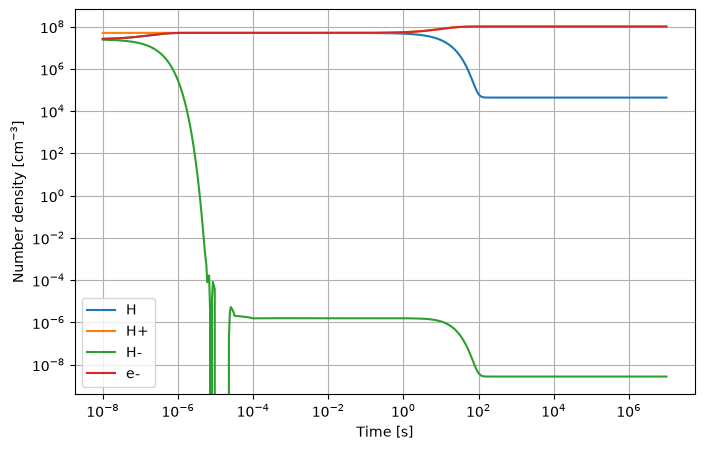

In [48]:
plt.figure(figsize=(8, 5))

plt.loglog(t_low, N_H_low, label="H")
plt.loglog(t_low, N_Hplus_low, label="H+")
plt.loglog(t_low, N_Hminus_low, label="H-")
plt.loglog(t_low, N_e_low, label="e-")

plt.xlabel("Time [s]")
plt.ylabel("Number density [cm$^{-3}$]")
plt.legend()
plt.grid()

plt.savefig("final.png", dpi=300)
plt.show()

In [47]:
print("Final low-density populations:")
print("H  =", N_H_low[-1])
print("H+ =", N_Hplus_low[-1])
print("H- =", N_Hminus_low[-1])
print("e- =", N_e_low[-1])

print("\nSaha checks:")

print(
    "S_H =",
    N_Hplus_low[-1] * N_e_low[-1] / N_H_low[-1]
)

print(
    "S_Hminus =",
    N_H_low[-1] * N_e_low[-1] / N_Hminus_low[-1]
)

Final low-density populations:
H  = 43440.494730998726
H+ = 99956559.50526237
H- = 2.713851497823371e-09
e- = 99956559.50526887

Saha checks:
S_H = 230000000000.00003
S_Hminus = 1.5999999999999997e+21
